In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image, ImageEnhance
import shutil
import json
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount('/content/drive')

BASE     = '/content/drive/MyDrive/CDT_Dataset'
IMAGE_FOLDER = f'{BASE}/images'
LABEL_CSV    = f'{BASE}/labels/ccss_labels_final.csv'

Mounted at /content/drive


In [ ]:
df = pd.read_csv(LABEL_CSV)
df['dementia_risk'] = df['dementia_risk'].astype(bool)

print(f'Total: {len(df)} รูป')
print(f'Normal  : {(~df["dementia_risk"]).sum()}')
print(f'Dementia: {df["dementia_risk"].sum()}')

Total: 6602 รูป
Normal  : 5622
Dementia: 980


In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    stratify=df['dementia_risk']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.67,
    random_state=42,
    stratify=temp_df['dementia_risk']
)

print(f'Train : {len(train_df)} รูป '
      f'(Dementia: {train_df["dementia_risk"].sum()})')
print(f'Val   : {len(val_df)} รูป '
      f'(Dementia: {val_df["dementia_risk"].sum()})')
print(f'Test  : {len(test_df)} รูป '
      f'(Dementia: {test_df["dementia_risk"].sum()})')

train_df.to_csv(f'{BASE}/labels/train.csv', index=False)
val_df.to_csv(f'{BASE}/labels/val.csv', index=False)
test_df.to_csv(f'{BASE}/labels/test.csv', index=False)

Train : 4621 รูป (Dementia: 686)
Val   : 653 รูป (Dementia: 97)
Test  : 1328 รูป (Dementia: 197)


In [ ]:
# Undersample Normal ลงเหลือ 2000 รูป
from sklearn.utils.class_weight import compute_class_weight

normal_df   = df[~df['dementia_risk']]
dementia_df = df[df['dementia_risk']]

print('ก่อน Undersample:')
print(f'  Normal  : {len(normal_df)}')
print(f'  Dementia: {len(dementia_df)}')
print(f'  Ratio   : {len(normal_df)/len(dementia_df):.1f}:1')

# สุ่ม Normal แค่ 2000 รูป
TARGET_NORMAL = 2000
normal_sampled = normal_df.sample(n=TARGET_NORMAL, random_state=42)

df_balanced = pd.concat(
    [normal_sampled, dementia_df],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\nหลัง Undersample:')
print(f'  Normal  : {(~df_balanced["dementia_risk"]).sum()}')
print(f'  Dementia: {df_balanced["dementia_risk"].sum()}')
print(f'  Total   : {len(df_balanced)}')
print(f'  Ratio   : {(~df_balanced["dementia_risk"]).sum() / df_balanced["dementia_risk"].sum():.1f}:1')

labels_array = df_balanced['dementia_risk'].astype(int).values
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=labels_array
)
class_weights = {0: round(float(weights[0]), 4),
                 1: round(float(weights[1]), 4)}

print(f'\nClass Weights:')
print(f'  Normal (0)  : {class_weights[0]}')
print(f'  Dementia (1): {class_weights[1]}')

with open(f'{BASE}/labels/class_weights.json', 'w') as f:
    json.dump(class_weights, f)

df = df_balanced

ก่อน Undersample:
  Normal  : 5622
  Dementia: 980
  Ratio   : 5.7:1

หลัง Undersample:
  Normal  : 2000
  Dementia: 980
  Total   : 2980
  Ratio   : 2.0:1

Class Weights:
  Normal (0)  : 0.745
  Dementia (1): 1.5204


In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    stratify=df['dementia_risk']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.67,
    random_state=42,
    stratify=temp_df['dementia_risk']
)

print(f'Train : {len(train_df)} รูป (Dementia: {train_df["dementia_risk"].sum()})')
print(f'Val   : {len(val_df)} รูป (Dementia: {val_df["dementia_risk"].sum()})')
print(f'Test  : {len(test_df)} รูป (Dementia: {test_df["dementia_risk"].sum()})')

train_df.to_csv(f'{BASE}/labels/train.csv', index=False)
val_df.to_csv(f'{BASE}/labels/val.csv', index=False)
test_df.to_csv(f'{BASE}/labels/test.csv', index=False)

Train : 2086 รูป (Dementia: 686)
Val   : 295 รูป (Dementia: 97)
Test  : 599 รูป (Dementia: 197)


In [ ]:
import random

def augment_image(img):
    # ปรับ brightness
    factor = random.uniform(0.8, 1.2)
    img = ImageEnhance.Brightness(img).enhance(factor)

    # ปรับ contrast
    factor = random.uniform(0.8, 1.2)
    img = ImageEnhance.Contrast(img).enhance(factor)

    # zoom in/out
    zoom = random.uniform(0.9, 1.1)
    w, h = img.size
    new_w, new_h = int(w * zoom), int(h * zoom)
    img = img.resize((new_w, new_h), Image.LANCZOS)

    # crop กลับขนาดเดิม
    left = (new_w - w) // 2
    top  = (new_h - h) // 2
    img  = img.crop((left, top, left + w, top + h))

    return img

In [ ]:
AUG_FOLDER = f'{BASE}/images_augmented'
import os
os.makedirs(AUG_FOLDER, exist_ok=True)

dementia_train = train_df[train_df['dementia_risk'] == True]
target_count   = 2000
current_count  = len(dementia_train)
need_more      = target_count - current_count

print(f'Dementia ใน train: {current_count} รูป')
print(f'ต้องการเพิ่ม    : {need_more} รูป')
print(f'เป้าหมาย        : {target_count} รูป')

aug_rows = []
generated = 0

while generated < need_more:
    for _, row in dementia_train.iterrows():
        if generated >= need_more:
            break

        img_path = f'{IMAGE_FOLDER}/{row["filename"]}'
        try:
            img = Image.open(img_path).convert('RGB')
            aug_img = augment_image(img)

            new_filename = f'aug_{generated:05d}_{row["filename"]}'
            new_filename = new_filename.replace('.tif', '.jpg')
            aug_img.save(f'{AUG_FOLDER}/{new_filename}',
                        'JPEG', quality=95)

            new_row = row.copy()
            new_row['filename'] = new_filename
            aug_rows.append(new_row)
            generated += 1

        except Exception as e:
            print(f'Error {row["filename"]}: {e}')
            continue


aug_df = pd.DataFrame(aug_rows)
train_augmented_df = pd.concat([train_df, aug_df], ignore_index=True)
train_augmented_df.to_csv(
    f'{BASE}/labels/train_aug_dem2000.csv',
    index=False
)

print(f'  Normal  : {(~train_augmented_df["dementia_risk"]).sum()}')
print(f'  Dementia: {train_augmented_df["dementia_risk"].sum()}')
print(f'  Total   : {len(train_augmented_df)}')
ratio = (~train_augmented_df["dementia_risk"]).sum() / train_augmented_df["dementia_risk"].sum()
print(f'  Ratio   : {ratio:.2f}:1')

Dementia ใน train: 686 รูป
ต้องการเพิ่ม    : 1314 รูป
เป้าหมาย        : 2000 รูป

สร้างรูป augmented: 1314 รูป

Train set หลัง augment:
  Normal  : 1400
  Dementia: 2000
  Total   : 3400
  Ratio   : 0.70:1


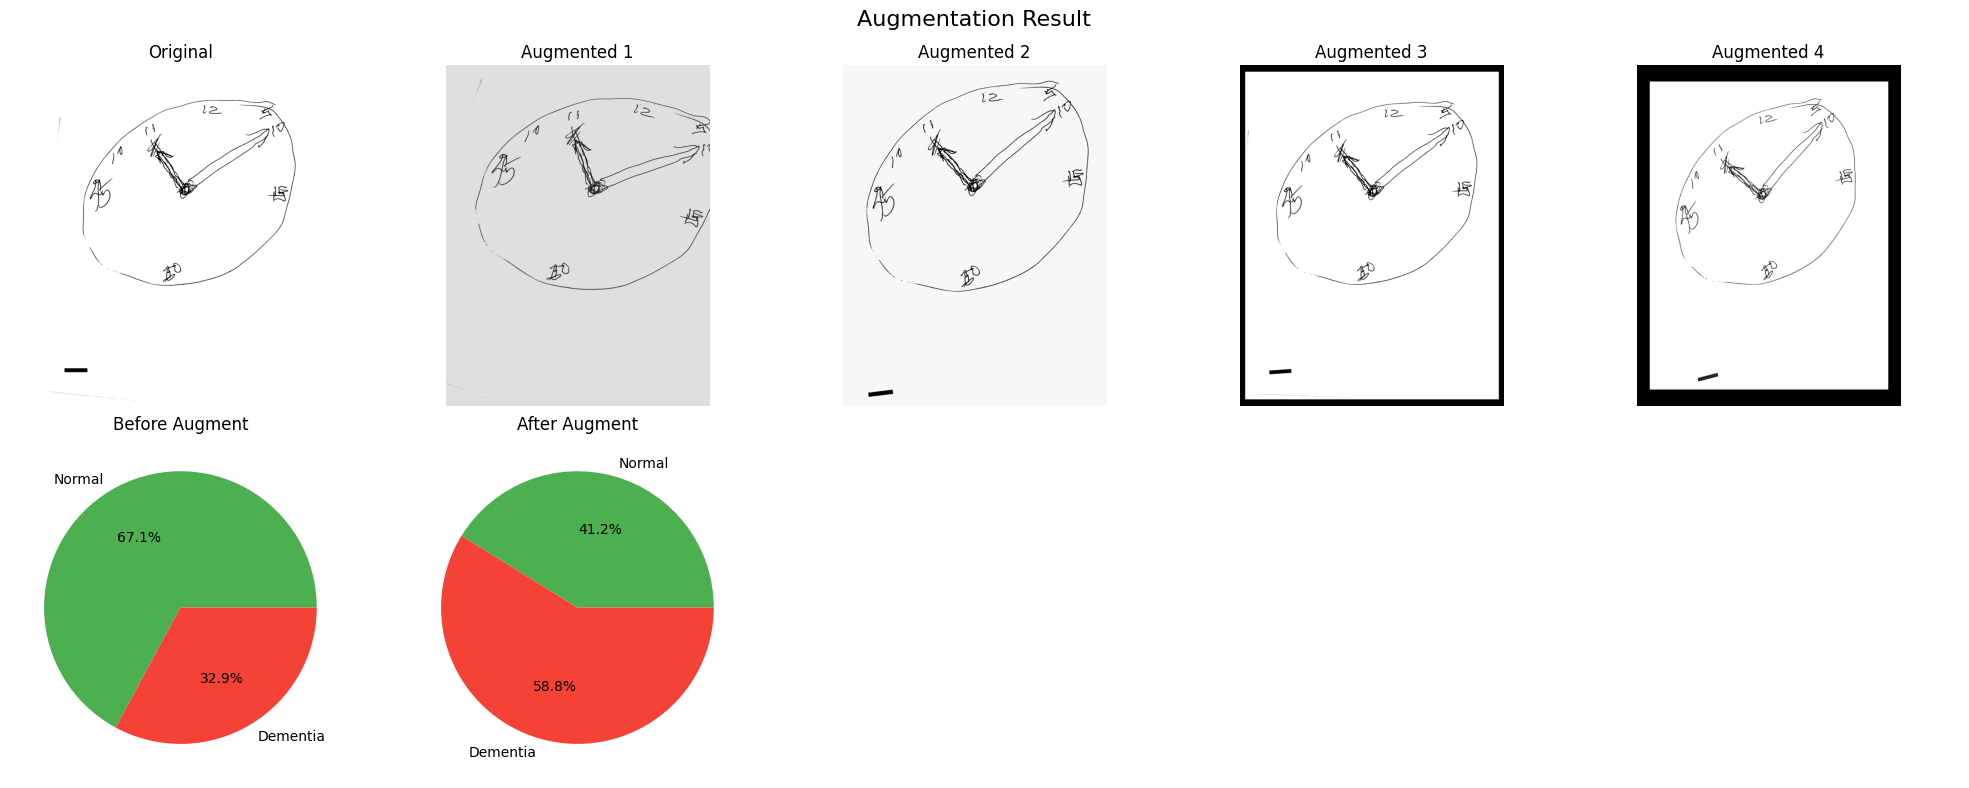

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

sample = dementia_train.iloc[0]
original = Image.open(
    f'{IMAGE_FOLDER}/{sample["filename"]}').convert('RGB')

axes[0][0].imshow(original)
axes[0][0].set_title('Original')
axes[0][0].axis('off')

for i in range(1, 5):
    aug = augment_image(original)
    axes[0][i].imshow(aug)
    axes[0][i].set_title(f'Augmented {i}')
    axes[0][i].axis('off')

counts_before = [
    (~train_df['dementia_risk']).sum(),
    train_df['dementia_risk'].sum()
]
counts_after = [
    (~train_augmented_df['dementia_risk']).sum(),
    train_augmented_df['dementia_risk'].sum()
]

axes[1][0].pie(counts_before,
               labels=['Normal', 'Dementia'],
               autopct='%1.1f%%',
               colors=['#4CAF50', '#F44336'])
axes[1][0].set_title('Before Augment')

axes[1][1].pie(counts_after,
               labels=['Normal', 'Dementia'],
               autopct='%1.1f%%',
               colors=['#4CAF50', '#F44336'])
axes[1][1].set_title('After Augment')

for i in range(2, 5):
    axes[1][i].axis('off')

plt.suptitle('Augmentation Result', fontsize=16)
plt.tight_layout()
plt.savefig(f'{BASE}/augmentation_result.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(f'  train.csv            : {len(train_df)} รูป')
print(f'  train_augmented.csv  : {len(train_augmented_df)} รูป')
print(f'  val.csv              : {len(val_df)} รูป')
print(f'  test.csv             : {len(test_df)} รูป')
print(f'  class_weights.json   : {class_weights}')
print(f'  images_augmented/    : {generated} รูป')

  train.csv            : 2086 รูป
  train_augmented.csv  : 3400 รูป
  val.csv              : 295 รูป
  test.csv             : 599 รูป
  class_weights.json   : {0: 0.745, 1: 1.5204}
  images_augmented/    : 1314 รูป
